# 02c · Host Plants

**Question:** Where are lanternfly host plants, and do counties with more hosts have more lanternflies? (EDA ToDo item 9)

| Source | Measures | Strength | Weakness |
|---|---|---|---|
| USFS FIA (EVALIDator API) | Estimated live trees per county by species, most recent statewide evaluation (mostly 2024–2025) | Designed random sample, includes absences | **Forest land only**; Tree of Heaven is rare on plots, so estimates are noisy; no data for many small cities |
| GBIF iNaturalist Tree of Heaven sightings, 2014–2025 | Reported sightings per county | Covers roadsides and urban areas where Tree of Heaven thrives | Presence-only, biased by observer effort |

Host groups from FIA: **Tree of Heaven** (*Ailanthus altissima*, primary host), black walnut, maples (*Acer*), willows (*Salix*).

> **AI-generated code (Claude Code).** See `docs/ai_usage.md`. *Team interpretation* cells are for the team to write.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds

YEARS = list(range(2014, 2026))
counties = ds.load_counties()
lower48 = counties[~counties["state"].isin(["AK", "HI", "PR"])]

def rho(x, y):
    ok = ~(np.isnan(x) | np.isnan(y))
    r, p = spearmanr(x[ok], y[ok])
    return r, p, ok.sum()

## 1. FIA host trees

In [2]:
fia = ds.fetch_fia_hosts()
wide = fia.pivot(index="fips", columns="host", values="trees").add_suffix("_trees")
share = fia.pivot(index="fips", columns="host", values="host_share").add_suffix("_share")
toh_se = fia[fia["host"] == "tree_of_heaven"].set_index("fips")["se"].rename("toh_se")
hosts = (wide.join(share).join(toh_se).join(fia.groupby("fips")["all_trees"].first())
             .reset_index().merge(lower48[["fips", "state", "county", "ALAND"]], on="fips", how="right"))
hosts["toh_per_km2"] = hosts["tree_of_heaven_trees"] / (hosts["ALAND"] / 1e6)

print(f"Lower-48 counties: {len(hosts):,}; with FIA data: {hosts['all_trees'].notna().sum():,}")
print("No FIA data, by state:", hosts[hosts["all_trees"].isna()]["state"].value_counts().head(6).to_dict())
t = hosts["tree_of_heaven_trees"]
print(f"Tree of Heaven > 0 in {(t > 0).sum()} of {t.notna().sum()} FIA counties")
print(f"Median relative SE where > 0: {(hosts['toh_se'] / t)[t > 0].median():.0%}")
hosts[[c for c in hosts.columns if c.endswith("_share")]].describe().round(3)

Lower-48 counties: 3,108; with FIA data: 2,724
No FIA data, by state: {'TX': 211, 'VA': 34, 'KS': 25, 'NE': 21, 'SD': 18, 'ND': 16}
Tree of Heaven > 0 in 395 of 2724 FIA counties
Median relative SE where > 0: 93%


,black_walnut_share,maple_share,tree_of_heaven_share,willow_share
count,2724.000,2724.000,2724.000,2724.000
mean,0.010,0.117,0.002,0.005
std,0.034,0.128,0.013,0.034
min,0.000,0.000,0.000,0.000
25%,0.000,0.007,0.000,0.000
50%,0.000,0.078,0.000,0.000
75%,0.005,0.193,0.000,0.000
max,0.795,1.000,0.476,1.000


Relative SEs near 100% mean single-county Tree of Heaven estimates are barely more than presence/absence. Most FIA zeros mean *not sampled on forest plots*, not *absent*.

## 2. GBIF Tree of Heaven sightings (effort-adjusted)

In [3]:
toh = ds.fetch_gbif_county_counts(YEARS, taxon_key=ds.GBIF_TOH_TAXON_KEY).groupby("fips")["n_obs"].sum().rename("toh_obs")
cy = pd.read_parquet(ds.PROCESSED / "county_year_effort.parquet")
tot = cy.groupby("fips")[["all_obs", "slf_obs"]].sum()

hosts = hosts.merge(toh, on="fips", how="left").merge(tot, on="fips", how="left").fillna({"toh_obs": 0})
hosts["toh_per_10k"] = np.where(hosts["all_obs"] >= 500, 1e4 * hosts["toh_obs"] / hosts["all_obs"], np.nan)
print(f"Counties with ≥1 Tree of Heaven sighting: {(hosts['toh_obs'] > 0).sum():,}")
print(f"…of which FIA reports 0 Tree of Heaven on forest land: "
      f"{((hosts['toh_obs'] > 0) & (hosts['tree_of_heaven_trees'] == 0)).sum():,}")

Counties with ≥1 Tree of Heaven sighting: 1,325
…of which FIA reports 0 Tree of Heaven on forest land: 881


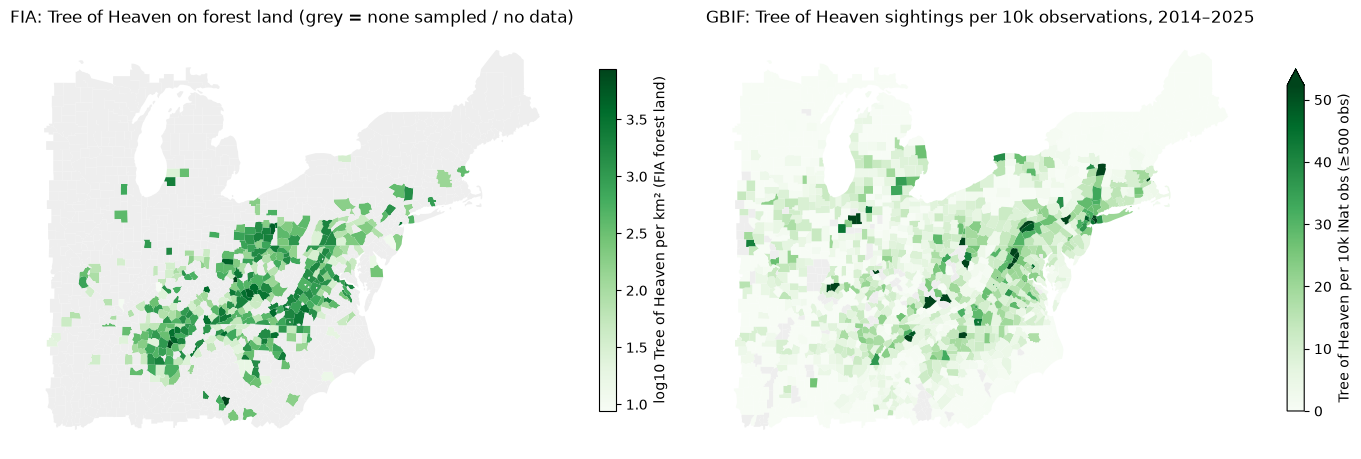

In [4]:
east = hosts.merge(lower48[["fips", "geometry"]], on="fips")
east = east.set_geometry("geometry").cx[-92:-66, 33:46]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
v = np.log10(east["toh_per_km2"].where(east["toh_per_km2"] > 0))
east.plot(column=v, ax=ax[0], cmap="Greens", legend=True, missing_kwds={"color": "#eee"},
          legend_kwds={"label": "log10 Tree of Heaven per km² (FIA forest land)", "shrink": .6})
r = east["toh_per_10k"]
east.plot(column=r, ax=ax[1], cmap="Greens", legend=True, vmax=r.quantile(.98), missing_kwds={"color": "#eee"},
          legend_kwds={"label": "Tree of Heaven per 10k iNat obs (≥500 obs)", "shrink": .6})
ax[0].set_title("FIA: Tree of Heaven on forest land (grey = none sampled / no data)")
ax[1].set_title("GBIF: Tree of Heaven sightings per 10k observations, 2014–2025")
for a in ax: a.set_axis_off()
plt.tight_layout()

## 3. Do the two sources agree?

In [5]:
both = hosts[hosts["all_trees"].notna()]
for name, x in [("FIA Tree of Heaven per km²", both["toh_per_km2"]), ("FIA Tree of Heaven share of trees", both["tree_of_heaven_share"])]:
    r, p, n = rho(x.to_numpy(float), both["toh_per_10k"].to_numpy(float))
    print(f"{name:36s} vs GBIF rate: Spearman ρ = {r:.2f} (p = {p:.1g}, n = {n:,})")

FIA Tree of Heaven per km²           vs GBIF rate: Spearman ρ = 0.42 (p = 9e-102, n = 2,409)
FIA Tree of Heaven share of trees    vs GBIF rate: Spearman ρ = 0.42 (p = 1e-101, n = 2,409)


## 4. Hosts vs. lanternflies

Restricted to the invasion region (counties in states with ≥100 lanternfly observations) and counties with ≥500 iNaturalist observations, so lanternfly rates aren't dominated by tiny denominators or never-reached states.

**Caution:** both Tree of Heaven and lanternflies are concentrated in the Mid-Atlantic, so a raw correlation mixes *host availability* with *distance from the 2014 introduction in PA*. This is a first look, not a causal estimate.

**Shared reporting:** lanternfly outreach campaigns also ask the public to report Tree of Heaven, so GBIF Tree of Heaven and lanternfly rates can rise together because of the same reporters. FIA is independent of iNaturalist, so its correlations aren't affected by this.

In [6]:
state_slf = hosts.groupby("state")["slf_obs"].sum()
inv = hosts[hosts["state"].isin(state_slf[state_slf >= 100].index) & (hosts["all_obs"] >= 500)].copy()
inv["slf_per_10k"] = 1e4 * inv["slf_obs"] / inv["all_obs"]
print(f"Invasion-region counties: {len(inv):,} in {inv['state'].nunique()} states")

rows = []
for col in ["toh_per_10k", "toh_per_km2", "tree_of_heaven_share", "black_walnut_share", "maple_share", "willow_share"]:
    r, p, n = rho(inv[col].to_numpy(float), inv["slf_per_10k"].to_numpy(float))
    rows.append({"host measure": col, "spearman_rho": r, "p_value": p, "n": n})
pd.DataFrame(rows).round(3)

Invasion-region counties: 560 in 13 states


,host measure,spearman_rho,p_value,n
0,toh_per_10k,0.527,0.000,560
1,toh_per_km2,0.181,0.000,528
2,tree_of_heaven_share,0.209,0.000,528
3,black_walnut_share,0.157,0.000,528
4,maple_share,0.072,0.099,528
5,willow_share,-0.196,0.000,528


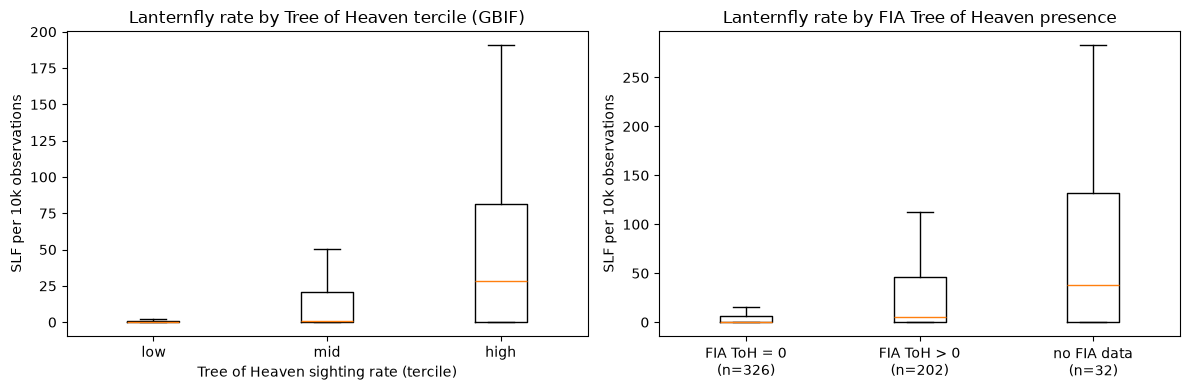

In [7]:
inv["toh_tercile"] = pd.qcut(inv["toh_per_10k"].rank(method="first"), 3, labels=["low", "mid", "high"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
groups = [inv.loc[inv["toh_tercile"] == k, "slf_per_10k"] for k in ["low", "mid", "high"]]
ax[0].boxplot(groups, tick_labels=["low", "mid", "high"], showfliers=False)
ax[0].set(xlabel="Tree of Heaven sighting rate (tercile)", ylabel="SLF per 10k observations",
          title="Lanternfly rate by Tree of Heaven tercile (GBIF)")
fia_any = inv["tree_of_heaven_trees"].gt(0).map({True: "FIA ToH > 0", False: "FIA ToH = 0"})
fia_any[inv["all_trees"].isna()] = "no FIA data"
cats = ["FIA ToH = 0", "FIA ToH > 0", "no FIA data"]
groups = [inv.loc[fia_any == k, "slf_per_10k"] for k in cats]
ax[1].boxplot(groups, tick_labels=[f"{k}\n(n={len(g)})" for k, g in zip(cats, groups)], showfliers=False)
ax[1].set(ylabel="SLF per 10k observations", title="Lanternfly rate by FIA Tree of Heaven presence")
plt.tight_layout()

### Team interpretation
_To be written by the team. Prompts:_
- How well do FIA and GBIF agree on where Tree of Heaven is? Which is more credible for our counties, and why?
- Do counties with more Tree of Heaven have more lanternflies, and how much of that could be geography (distance from PA)?
- **Decision:** which host feature(s) go in the model: FIA share, FIA presence, GBIF rate, or a combination? How do we handle counties with no FIA data (e.g., Virginia's independent cities)?

In [8]:
cols = ["fips", "state", "county", "all_trees", "toh_se", "toh_per_km2", "toh_obs", "toh_per_10k"] + \
       [c for c in hosts.columns if c.endswith(("_trees", "_share")) and c != "all_trees"]
hosts[cols].to_parquet(ds.PROCESSED / "county_hosts.parquet", index=False)
print(sorted(cols))

['all_trees', 'black_walnut_share', 'black_walnut_trees', 'county', 'fips', 'maple_share', 'maple_trees', 'state', 'toh_obs', 'toh_per_10k', 'toh_per_km2', 'toh_se', 'tree_of_heaven_share', 'tree_of_heaven_trees', 'willow_share', 'willow_trees']
